# PathSnap — Step 4: Exploratory Data Analysis

Profiles every trip in `data/train` (80) and `data/student_test` (10) and writes
`outputs/eda_summary.csv`.

**This notebook is strictly read-only — it never modifies the dataset.**

### What is computed per trip

GPS point count · duration · bounding box · GPS trajectory length (haversine) ·
node count · arc count · route arc count · geometric reference route length ·
mean/median/min/max Δt · count of Δt > 2 s gaps · road-graph connected
components · GPS missing-value count · route chain breaks and max gap ·
the per-trip UTM EPSG code.

### Flags raised

non-monotonic timestamps · duplicate timestamps · NaN/invalid coordinates ·
GPS outside plausible geographic bounds · invalid node references in arcs ·
invalid arc references in routes · disconnected consecutive route arcs ·
empty files · unexpected GPS-vs-route length relationship.

### Dataset facts established earlier (not assumptions)

- Each trip ships **its own road graph**; `node_id`/`arc_id` are trip-local row indices.
- `.route` is **not** one-to-one with `.track` (e.g. trip `00000001`: 1315 points vs 525 arcs).
- Trips are spread **worldwide** (lon −100.4…+137.2, lat −34.6…+61.7), so every
  metre computation uses a **per-trip UTM CRS** via `geo_utils.project_local`.
- The route chain is only **piecewise**-continuous: 11 trips contain genuine gaps.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree

# Project layout: this notebook lives in notebooks/, sources in src/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import io_utils as io
import geo_utils as geo

DATA = ROOT / "data"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

PARTITIONS = ("train", "student_test")   # evaluator test data is never touched

pd.set_option("display.width", 200, "display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "figure.autolayout": True})

print("root:", ROOT)
for p in PARTITIONS:
    print(f"  {p}: {len(io.list_trips(DATA / p))} trips")

root: C:\Users\LENOVO\ML Hackathon
  train: 80 trips
  student_test: 10 trips


## 1. Per-trip summary

Two thresholds are named here rather than buried in the code:

- **`GAP_DT_S = 2.0`** — a Δt above this counts as a sampling gap (per the brief).
- **`FAR_FROM_GRAPH_M = 5000`** — a GPS point further than this from the trip's own
  node bounding box is treated as geographically implausible *for that trip*. Plain
  coordinate-range checks (|lon| ≤ 180, |lat| ≤ 90) cannot catch a point dropped in
  the wrong country, and since trips are worldwide there is no single valid box.

Route length is summed over the individual arcs (`from_node → to_node` haversine),
so the **gaps between broken chains are deliberately not counted** as travelled
distance.

In [2]:
GAP_DT_S = 2.0
FAR_FROM_GRAPH_M = 5000.0
#: GPS/route length ratio outside this band is flagged as suspicious
LENGTH_RATIO_BAND = (0.5, 2.0)


def graph_components(n_nodes: int, arcs: pd.DataFrame) -> tuple[int, float]:
    """Undirected connected components of a trip's road graph.

    Returns
    -------
    (n_components, largest_component_fraction)
        Components counted over *all* nodes, so isolated nodes count as their
        own component. Treating arcs as undirected answers "is this road
        network one piece?", which is what matters for map matching;
        one-way direction is handled later as a feature, not a hard barrier.
    """
    if n_nodes == 0:
        return 0, float("nan")
    if len(arcs) == 0:
        return n_nodes, 1.0 / n_nodes
    rows = arcs["from_node"].to_numpy()
    cols = arcs["to_node"].to_numpy()
    ok = (rows >= 0) & (rows < n_nodes) & (cols >= 0) & (cols < n_nodes)
    data = np.ones(ok.sum(), dtype=np.int8)
    adj = coo_matrix((data, (rows[ok], cols[ok])), shape=(n_nodes, n_nodes))
    n_comp, labels = connected_components(adj, directed=False)
    largest = np.bincount(labels).max() / n_nodes
    return int(n_comp), float(largest)


def arc_lengths_m(arcs: pd.DataFrame, nodes: pd.DataFrame) -> np.ndarray:
    """Haversine length of every arc, in metres, indexed like `arcs`."""
    lon = nodes["lon"].to_numpy()
    lat = nodes["lat"].to_numpy()
    a = arcs["from_node"].to_numpy()
    b = arcs["to_node"].to_numpy()
    n = len(nodes)
    ok = (a >= 0) & (a < n) & (b >= 0) & (b < n)
    out = np.full(len(arcs), np.nan)
    out[ok] = geo.haversine_m(lon[a[ok]], lat[a[ok]], lon[b[ok]], lat[b[ok]])
    return out


def nearest_arc_dist_m(
    proj: dict,
    arcs: pd.DataFrame,
    arc_ids: np.ndarray | None = None,
    k: int = 24,
    max_points: int = 4000,
) -> np.ndarray:
    """Distance from each GPS point to the nearest arc, in projected metres.

    Approximate-then-exact: a KD-tree over three representative points per
    arc (both endpoints and the midpoint) narrows to `k` candidate arcs, then
    the exact point-to-segment distance is taken over those. This is a
    *diagnostic* here -- Step 6 does the real thing with an R-tree over arc
    bounding boxes -- but it is accurate enough to predict whether a 50 m
    candidate radius can work at all.

    Parameters
    ----------
    proj
        Output of `geo.project_trip`.
    arcs
        The trip's arc table.
    arc_ids
        Restrict to this subset of arcs (e.g. the ground-truth route).
        None means the whole graph.
    k
        Candidate arcs pulled from the KD-tree per GPS point.
    max_points
        GPS points are evenly subsampled to at most this many, to keep the
        notebook responsive on the 19k-point trips.
    """
    a_all = arcs["from_node"].to_numpy()
    b_all = arcs["to_node"].to_numpy()
    ids = np.arange(len(arcs)) if arc_ids is None else np.asarray(arc_ids)
    if ids.size == 0:
        return np.array([])
    a, b = a_all[ids], b_all[ids]
    nx_, ny_ = proj["node_x"], proj["node_y"]
    ax, ay, bx, by = nx_[a], ny_[a], nx_[b], ny_[b]

    reps = np.column_stack([
        np.concatenate([ax, bx, (ax + bx) / 2.0]),
        np.concatenate([ay, by, (ay + by) / 2.0]),
    ])
    owner = np.tile(np.arange(ids.size), 3)
    tree = cKDTree(reps)

    px, py = proj["track_x"], proj["track_y"]
    if px.size > max_points:
        sel = np.linspace(0, px.size - 1, max_points).astype(int)
        px, py = px[sel], py[sel]
    _, idx = tree.query(np.column_stack([px, py]), k=min(k, len(reps)), workers=-1)
    idx = np.atleast_2d(idx)
    cand = owner[idx]
    d = geo.point_to_segment_dist_m(
        px[:, None], py[:, None], ax[cand], ay[cand], bx[cand], by[cand]
    )
    return d.min(axis=1)


def summarize_trip(partition: str, trip_id: str) -> dict:
    """Profile one trip. Never raises: load failures are recorded as flags."""
    trip_dir = DATA / partition / trip_id
    rec: dict = {"partition": partition, "trip_id": trip_id}

    # --- empty / unreadable files are a flag, not a crash ------------------
    sizes = {
        ext: (trip_dir / f"{trip_id}.{ext}").stat().st_size
        for ext in io.TRIP_EXTENSIONS
    }
    rec["empty_files"] = ",".join(sorted(e for e, s in sizes.items() if s == 0))
    try:
        trip = io.load_trip(trip_dir)
    except io.TripDataError as exc:
        rec["load_error"] = str(exc)
        return rec
    rec["load_error"] = ""

    track, nodes, arcs, route = trip["track"], trip["nodes"], trip["arcs"], trip["route"]
    lon = track["lon"].to_numpy()
    lat = track["lat"].to_numpy()
    t = track["t_sec"].to_numpy()

    # --- counts ------------------------------------------------------------
    rec["n_gps"] = len(track)
    rec["n_nodes"] = len(nodes)
    rec["n_arcs"] = len(arcs)
    rec["n_route_arcs"] = int(route.size)
    rec["gps_missing_values"] = int(track[["lon", "lat", "t_sec"]].isna().to_numpy().sum())

    # --- projection actually used for this trip ----------------------------
    rec["utm_epsg"] = geo.get_trip_epsg(trip)

    # --- time --------------------------------------------------------------
    rec["t_start_s"] = float(t.min()) if t.size else np.nan
    rec["t_end_s"] = float(t.max()) if t.size else np.nan
    rec["duration_s"] = float(t.max() - t.min()) if t.size else np.nan
    dt = np.diff(t) if t.size > 1 else np.array([])
    rec["dt_mean_s"] = float(np.nanmean(dt)) if dt.size else np.nan
    rec["dt_median_s"] = float(np.nanmedian(dt)) if dt.size else np.nan
    rec["dt_min_s"] = float(np.nanmin(dt)) if dt.size else np.nan
    rec["dt_max_s"] = float(np.nanmax(dt)) if dt.size else np.nan
    rec["n_gaps_dt_gt_2s"] = int(np.count_nonzero(dt > GAP_DT_S))

    # --- geography ---------------------------------------------------------
    rec["lon_min"], rec["lon_max"] = float(np.nanmin(lon)), float(np.nanmax(lon))
    rec["lat_min"], rec["lat_max"] = float(np.nanmin(lat)), float(np.nanmax(lat))
    rec["gps_length_m"] = float(
        np.nansum(geo.haversine_m(lon[:-1], lat[:-1], lon[1:], lat[1:]))
    ) if len(track) > 1 else 0.0

    # --- road graph --------------------------------------------------------
    rec["graph_components"], rec["largest_cc_frac"] = graph_components(len(nodes), arcs)

    # --- reference route geometry -----------------------------------------
    alen = arc_lengths_m(arcs, nodes)
    in_range = (route >= 0) & (route < len(arcs))
    rec["route_length_m"] = float(np.nansum(alen[route[in_range]])) if in_range.any() else 0.0
    rec["arc_len_median_m"] = float(np.nanmedian(alen)) if len(alen) else np.nan

    breaks = io.route_chain_breaks(route, arcs, nodes)
    rec["route_chain_breaks"] = int(len(breaks))
    rec["max_gap_m"] = float(np.nanmax(breaks["gap_m"])) if len(breaks) else 0.0
    rec["n_route_segments"] = len(io.route_segments(route, arcs))

    # --- ratios that make the numbers comparable across trips -------------
    rec["gps_per_route_arc"] = rec["n_gps"] / rec["n_route_arcs"] if rec["n_route_arcs"] else np.nan
    rec["length_ratio_gps_route"] = (
        rec["gps_length_m"] / rec["route_length_m"] if rec["route_length_m"] > 0 else np.nan
    )

    # --- flags -------------------------------------------------------------
    rec["flag_nonmonotonic_time"] = bool(np.any(dt < 0)) if dt.size else False
    rec["n_dup_timestamps"] = int(pd.Series(t).duplicated().sum())
    rec["flag_dup_timestamps"] = rec["n_dup_timestamps"] > 0
    rec["flag_nan_coords"] = bool(np.isnan(lon).any() or np.isnan(lat).any())
    rec["flag_coords_out_of_range"] = bool(
        np.any(np.abs(lon) > 180) or np.any(np.abs(lat) > 90)
    )

    # plausibility relative to the trip's own graph, in projected metres
    px, py = geo.project_local(lon, lat, trip_id, trip_data=trip)
    nx_, ny_ = geo.project_local(nodes["lon"].to_numpy(), nodes["lat"].to_numpy(), trip_id)
    dx = np.maximum(0.0, np.maximum(nx_.min() - px, px - nx_.max()))
    dy = np.maximum(0.0, np.maximum(ny_.min() - py, py - ny_.max()))
    dist_outside = np.hypot(dx, dy)
    rec["gps_max_dist_outside_graph_bbox_m"] = float(np.nanmax(dist_outside))
    rec["n_gps_far_from_graph"] = int(np.count_nonzero(dist_outside > FAR_FROM_GRAPH_M))
    rec["flag_gps_far_from_graph"] = rec["n_gps_far_from_graph"] > 0

    # --- how close is the GPS to the network, and to the route? -----------
    # Decisive for Step 6: if the true arc is not within the candidate radius
    # R, no model can recover it. Computed here so the radius is chosen from
    # evidence rather than guessed.
    proj = {
        "track_x": px, "track_y": py,
        "node_x": nx_, "node_y": ny_,
    }
    d_graph = nearest_arc_dist_m(proj, arcs)
    rec["gps_graph_dist_median_m"] = float(np.median(d_graph))
    rec["gps_graph_dist_p95_m"] = float(np.percentile(d_graph, 95))
    rec["frac_gps_within_50m_of_graph"] = float(np.mean(d_graph <= 50.0))
    rec["flag_gps_offset_from_graph"] = bool(rec["gps_graph_dist_median_m"] > 25.0)

    d_route = nearest_arc_dist_m(proj, arcs, route[in_range])
    rec["gps_route_dist_median_m"] = float(np.median(d_route)) if d_route.size else np.nan
    rec["frac_gps_within_50m_of_route"] = float(np.mean(d_route <= 50.0)) if d_route.size else np.nan
    rec["flag_gps_offset_from_route"] = bool(
        d_route.size and rec["gps_route_dist_median_m"] > 25.0
    )

    node_refs = arcs[list(io.ARC_COLUMNS)].to_numpy()
    rec["n_invalid_node_refs"] = int(
        np.count_nonzero(((node_refs < 0) | (node_refs >= len(nodes))).any(axis=1))
    )
    rec["flag_invalid_node_refs"] = rec["n_invalid_node_refs"] > 0
    rec["n_invalid_arc_refs"] = int(np.count_nonzero(~in_range))
    rec["flag_invalid_arc_refs"] = rec["n_invalid_arc_refs"] > 0
    rec["flag_route_disconnected"] = rec["route_chain_breaks"] > 0
    lo, hi = LENGTH_RATIO_BAND
    r = rec["length_ratio_gps_route"]
    rec["flag_length_ratio_odd"] = bool(np.isnan(r) or r < lo or r > hi)
    rec["flag_empty_files"] = bool(rec["empty_files"])
    return rec

In [3]:
records = []
for part in PARTITIONS:
    for trip_id in io.list_trips(DATA / part):
        records.append(summarize_trip(part, trip_id))

summary = pd.DataFrame.from_records(records)
print(summary.shape)
summary.head(3).T

(90, 54)


,0,1,2
partition,train,train,train
trip_id,00000001,00000002,00000003
empty_files,,,
load_error,,,
n_gps,1315,7243,821
n_nodes,88809,7936,9138
n_arcs,165790,16139,18028
n_route_arcs,525,262,79
gps_missing_values,0,0,0
utm_epsg,32632,32632,32637


## 2. Save the summary

In [4]:
csv_path = OUT / "eda_summary.csv"
summary.to_csv(csv_path, index=False)
print("wrote", csv_path, "->", summary.shape[0], "rows x", summary.shape[1], "columns")
print("\ncolumns:")
print(", ".join(summary.columns))

wrote C:\Users\LENOVO\ML Hackathon\outputs\eda_summary.csv -> 90 rows x 54 columns

columns:
partition, trip_id, empty_files, load_error, n_gps, n_nodes, n_arcs, n_route_arcs, gps_missing_values, utm_epsg, t_start_s, t_end_s, duration_s, dt_mean_s, dt_median_s, dt_min_s, dt_max_s, n_gaps_dt_gt_2s, lon_min, lon_max, lat_min, lat_max, gps_length_m, graph_components, largest_cc_frac, route_length_m, arc_len_median_m, route_chain_breaks, max_gap_m, n_route_segments, gps_per_route_arc, length_ratio_gps_route, flag_nonmonotonic_time, n_dup_timestamps, flag_dup_timestamps, flag_nan_coords, flag_coords_out_of_range, gps_max_dist_outside_graph_bbox_m, n_gps_far_from_graph, flag_gps_far_from_graph, gps_graph_dist_median_m, gps_graph_dist_p95_m, frac_gps_within_50m_of_graph, flag_gps_offset_from_graph, gps_route_dist_median_m, frac_gps_within_50m_of_route, flag_gps_offset_from_route, n_invalid_node_refs, flag_invalid_node_refs, n_invalid_arc_refs, flag_invalid_arc_refs, flag_route_disconnected, f

## 3. Scale of the data

In [5]:
cols = ["n_gps", "duration_s", "gps_length_m", "n_nodes", "n_arcs",
        "n_route_arcs", "route_length_m", "gps_per_route_arc",
        "dt_median_s", "dt_max_s", "n_gaps_dt_gt_2s", "graph_components"]
summary.groupby("partition")[cols].describe().T.round(2)

partition               student_test    train
n_gps            count         10.00    80.00
                 mean        1916.00  2605.21
                 std         1335.43  3312.35
                 min          262.00   361.00
                 25%          917.75   945.75
...                              ...      ...
graph_components min            5.00     1.00
                 25%            7.25     9.75
                 50%           11.00    20.00
                 75%           21.75    42.25
                 max          100.00   421.00

[96 rows x 2 columns]

## 4. Flags

Every flag column, counted per partition. A flag is a *finding*, not a reason to
drop a trip: the route-chain breaks in particular are real ground-truth
discontinuities that the Step 8 alignment has to cope with.

In [6]:
flag_cols = [c for c in summary.columns if c.startswith("flag_")]
flag_counts = summary.groupby("partition")[flag_cols].sum().T
flag_counts["total"] = flag_counts.sum(axis=1)
flag_counts

partition,student_test,train,total
flag_nonmonotonic_time,0,0,0
flag_dup_timestamps,0,0,0
flag_nan_coords,0,0,0
flag_coords_out_of_range,0,0,0
flag_gps_far_from_graph,0,0,0
flag_gps_offset_from_graph,0,1,1
flag_gps_offset_from_route,0,2,2
flag_invalid_node_refs,0,0,0
flag_invalid_arc_refs,0,0,0
flag_route_disconnected,1,10,11


In [7]:
flagged = summary[summary[flag_cols].any(axis=1)]
print(f"{len(flagged)} of {len(summary)} trips raise at least one flag\n")
flagged[["partition", "trip_id", "n_gps", "n_route_arcs", "route_chain_breaks",
         "max_gap_m", "length_ratio_gps_route", "graph_components",
         "largest_cc_frac", "n_gps_far_from_graph"] + flag_cols].reset_index(drop=True)

19 of 90 trips raise at least one flag



,partition,trip_id,n_gps,n_route_arcs,route_chain_breaks,max_gap_m,length_ratio_gps_route,graph_components,largest_cc_frac,n_gps_far_from_graph,flag_nonmonotonic_time,flag_dup_timestamps,flag_nan_coords,flag_coords_out_of_range,flag_gps_far_from_graph,flag_gps_offset_from_graph,flag_gps_offset_from_route,flag_invalid_node_refs,flag_invalid_arc_refs,flag_route_disconnected,flag_length_ratio_odd,flag_empty_files
0,train,00000002,7243,262,1,324.678998,7.016339,14,0.976562,0,False,False,False,False,False,False,False,False,False,True,True,False
1,train,00000008,3093,173,0,0.000000,2.678847,13,0.983584,0,False,False,False,False,False,False,False,False,False,False,True,False
2,train,00000010,2711,210,0,0.000000,2.263663,28,0.934016,0,False,False,False,False,False,False,False,False,False,False,True,False
3,train,00000019,2354,545,3,595.814100,1.141291,90,0.970585,0,False,False,False,False,False,False,False,False,False,True,False,False
4,train,00000021,15783,277,0,0.000000,2.650512,3,0.950820,0,False,False,False,False,False,False,False,False,False,False,True,False
5,train,00000033,5844,169,1,91.934327,7.498425,7,0.985928,0,False,False,False,False,False,False,True,False,False,True,True,False
6,train,00000041,1019,340,1,57.227432,1.153435,11,0.989537,0,False,False,False,False,False,False,False,False,False,True,False,False
7,train,00000042,7739,1440,1,30.724827,1.218285,73,0.942766,0,False,False,False,False,False,False,False,False,False,True,False,False
8,train,00000046,1401,66,0,0.000000,2.023113,2,0.989967,0,False,False,False,False,False,False,False,False,False,False,True,False
9,train,00000054,19313,422,0,0.000000,5.396622,213,0.970371,0,False,False,False,False,False,True,True,False,False,False,True,False


### Per-trip UTM EPSG codes

Logged so the projection used for each trip is inspectable, as the
single-fixed-CRS assumption does not hold for this dataset.

In [8]:
epsg_counts = summary["utm_epsg"].value_counts().sort_index()
print(f"{len(epsg_counts)} distinct UTM zones across {len(summary)} trips")
print(f"southern hemisphere (327xx): "
      f"{int(summary['utm_epsg'].between(32700, 32799).sum())} trips")
print(epsg_counts.to_string())
summary[["partition", "trip_id", "utm_epsg", "lon_min", "lon_max",
         "lat_min", "lat_max"]].head(10)

25 distinct UTM zones across 90 trips
southern hemisphere (327xx): 3 trips
utm_epsg
32614     1
32615     2
32616     2
32617     3
32622     1
32629     3
32630     9
32631     7
32632     8
32633     7
32634     5
32635     3
32636     5
32637    10
32638     4
32639     4
32640     2
32641     4
32643     2
32648     1
32651     1
32653     3
32721     1
32722     1
32735     1


,partition,trip_id,utm_epsg,lon_min,lon_max,lat_min,lat_max
0,train,00000001,32632,8.570524,8.647860,49.844053,50.211882
1,train,00000002,32632,10.999961,11.050902,47.658344,47.695459
2,train,00000003,32637,37.154202,37.201595,55.977135,56.007585
3,train,00000004,32633,12.342280,12.459615,52.590308,52.718960
4,train,00000005,32636,35.485577,35.544315,49.357581,49.613085
5,train,00000006,32637,37.276002,37.317675,55.429164,55.487229
6,train,00000008,32616,-86.584860,-86.567487,34.733275,34.753704
7,train,00000010,32637,37.357893,37.394790,55.786261,55.832857
8,train,00000011,32640,59.647057,60.016866,56.041788,56.067535
9,train,00000012,32638,44.044515,44.389906,36.175914,36.263587


### Can a 50 m candidate radius work?

`frac_gps_within_50m_of_route` is an **upper bound on achievable accuracy** for
Step 6: where the ground-truth arc is further than R from the GPS point, no
candidate set can contain it and no model can recover it. A low value means a
systematic offset between the GPS track and the road graph, not model error.

In [9]:
prox = summary[["partition", "trip_id", "gps_graph_dist_median_m",
                "gps_graph_dist_p95_m", "frac_gps_within_50m_of_graph",
                "gps_route_dist_median_m", "frac_gps_within_50m_of_route",
                "length_ratio_gps_route"]].copy()

print("distance from GPS to nearest arc in the trip's own graph (m):")
print(prox.gps_graph_dist_median_m.describe(percentiles=[.5, .9]).round(2).to_string())
print(f"\ntrips where the median GPS point is >25 m from ANY arc: "
      f"{int(summary.flag_gps_offset_from_graph.sum())}")
print(f"trips where the median GPS point is >25 m from its ROUTE: "
      f"{int(summary.flag_gps_offset_from_route.sum())}")

worst = prox.sort_values("frac_gps_within_50m_of_route").head(12).reset_index(drop=True)
print("\nworst trips by fraction of GPS points within 50 m of the ground-truth route:")
worst.round(3)

distance from GPS to nearest arc in the trip's own graph (m):
count    90.00
mean      5.31
std       8.46
min       2.56
50%       4.25
90%       5.85
max      84.17

trips where the median GPS point is >25 m from ANY arc: 1
trips where the median GPS point is >25 m from its ROUTE: 2

worst trips by fraction of GPS points within 50 m of the ground-truth route:


,partition,trip_id,gps_graph_dist_median_m,gps_graph_dist_p95_m,frac_gps_within_50m_of_graph,gps_route_dist_median_m,frac_gps_within_50m_of_route,length_ratio_gps_route
0,train,00000054,84.168,100.967,0.145,138.379,0.127,5.397
1,train,00000033,7.026,30.292,0.992,123.025,0.410,7.498
2,train,00000002,5.383,67.451,0.931,5.633,0.880,7.016
3,train,00000043,7.133,33.460,0.975,10.985,0.928,1.076
4,train,00000096,4.318,68.987,0.940,4.440,0.956,1.118
5,train,00000066,6.261,29.681,0.956,6.401,0.957,1.141
6,train,00000084,6.284,36.967,0.963,6.623,0.963,2.343
7,train,00000081,4.271,38.606,0.968,4.381,0.969,1.481
8,train,00000019,4.614,13.580,1.000,5.509,0.983,1.141
9,train,00000020,5.409,23.552,0.989,5.460,0.985,1.092


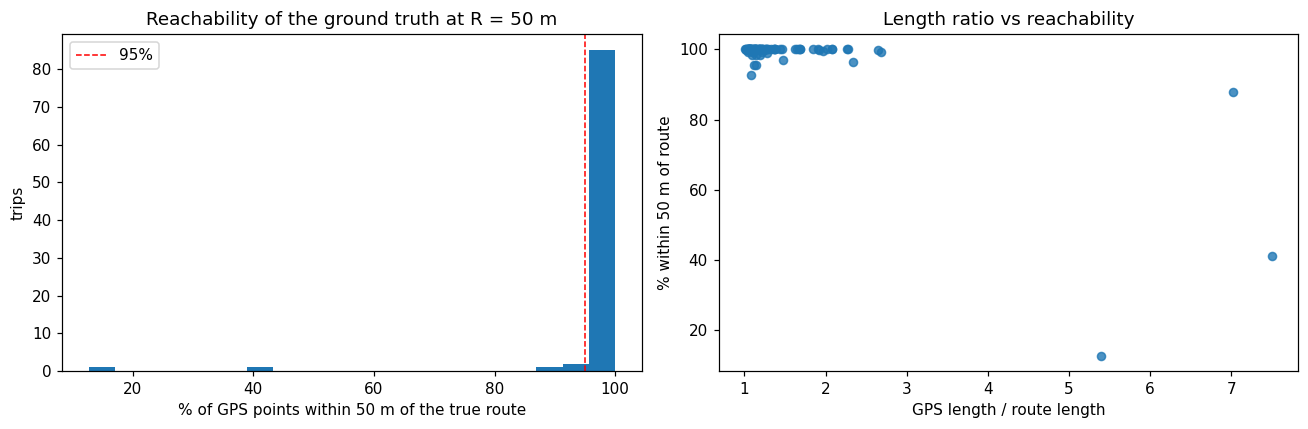

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(summary.frac_gps_within_50m_of_route * 100, bins=20)
ax[0].set(xlabel="% of GPS points within 50 m of the true route", ylabel="trips",
          title="Reachability of the ground truth at R = 50 m")
ax[0].axvline(95, color="red", ls="--", lw=1, label="95%")
ax[0].legend()
ax[1].scatter(summary.length_ratio_gps_route, summary.frac_gps_within_50m_of_route * 100,
              s=28, alpha=0.8)
ax[1].set(xlabel="GPS length / route length", ylabel="% within 50 m of route",
          title="Length ratio vs reachability")
fig.savefig(FIG / "route_reachability.png")
plt.show()

## 5. Plots

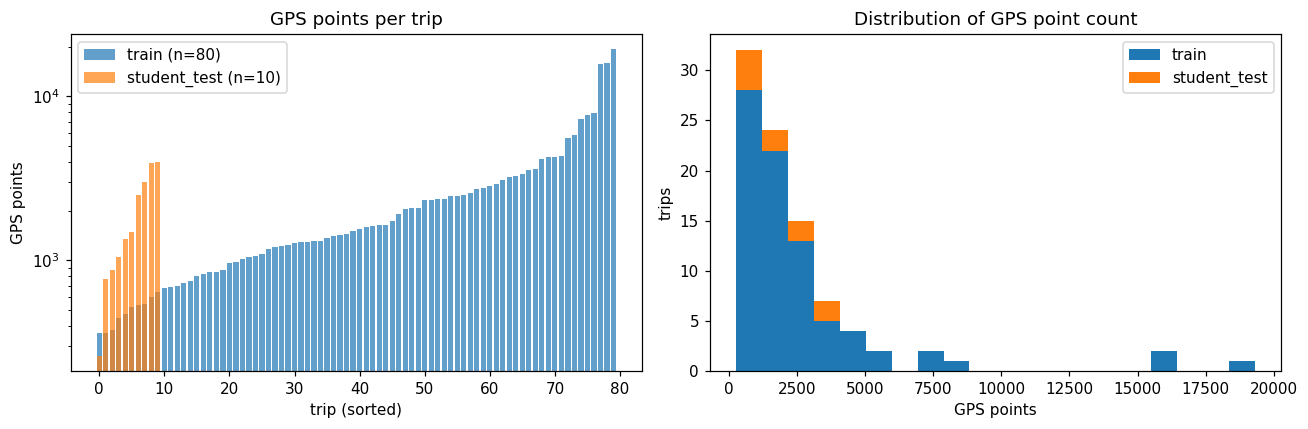

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, part in enumerate(PARTITIONS):
    s = summary.loc[summary.partition == part, "n_gps"]
    ax[0].bar(np.arange(len(s)) + i * 0.0, s.sort_values().to_numpy(),
              alpha=0.7, label=f"{part} (n={len(s)})")
ax[0].set(xlabel="trip (sorted)", ylabel="GPS points", yscale="log",
          title="GPS points per trip")
ax[0].legend()
ax[1].hist([summary.loc[summary.partition == p, "n_gps"] for p in PARTITIONS],
           bins=20, stacked=True, label=list(PARTITIONS))
ax[1].set(xlabel="GPS points", ylabel="trips", title="Distribution of GPS point count")
ax[1].legend()
fig.savefig(FIG / "gps_points_per_trip.png")
plt.show()

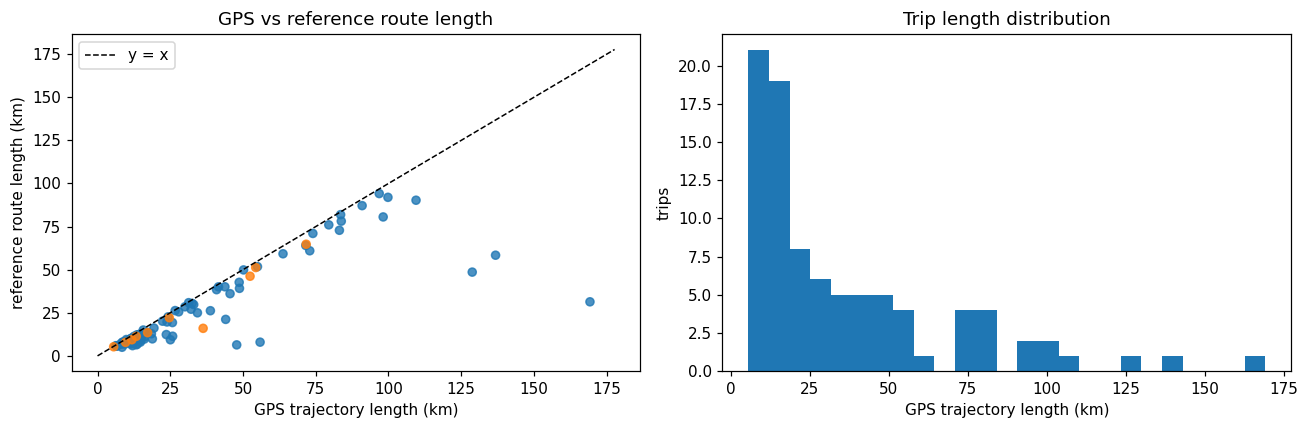

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(summary.gps_length_m / 1000, summary.route_length_m / 1000,
              c=(summary.partition == "train").map({True: "tab:blue", False: "tab:orange"}),
              s=28, alpha=0.8)
lim = max(summary.gps_length_m.max(), summary.route_length_m.max()) / 1000 * 1.05
ax[0].plot([0, lim], [0, lim], "k--", lw=1, label="y = x")
ax[0].set(xlabel="GPS trajectory length (km)", ylabel="reference route length (km)",
          title="GPS vs reference route length")
ax[0].legend()
ax[1].hist(summary.gps_length_m / 1000, bins=25)
ax[1].set(xlabel="GPS trajectory length (km)", ylabel="trips",
          title="Trip length distribution")
fig.savefig(FIG / "trip_length.png")
plt.show()

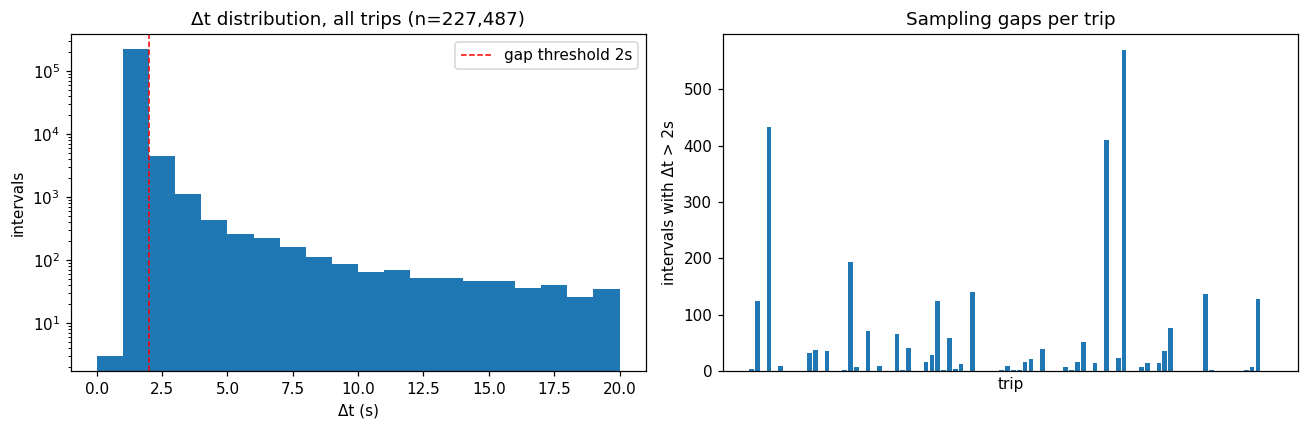

Δt percentiles (s):
count    227487.000
mean          2.087
std         339.588
min           1.000
50%           1.000
90%           1.000
99%           3.000
99.9%        20.000
max      153064.000


In [13]:
# Pooled Δt across every trip, read fresh (read-only) so the plot does not
# depend on summary statistics alone.
all_dt = []
for part in PARTITIONS:
    for trip_id in io.list_trips(DATA / part):
        t = io.load_track(DATA / part / trip_id / f"{trip_id}.track")["t_sec"].to_numpy()
        if t.size > 1:
            all_dt.append(np.diff(t))
all_dt = np.concatenate(all_dt)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(all_dt, bins=np.arange(0, 21, 1))
ax[0].set(xlabel="Δt (s)", ylabel="intervals", yscale="log",
          title=f"Δt distribution, all trips (n={all_dt.size:,})")
ax[0].axvline(GAP_DT_S, color="red", ls="--", lw=1, label=f"gap threshold {GAP_DT_S:g}s")
ax[0].legend()
ax[1].bar(summary.trip_id, summary.n_gaps_dt_gt_2s)
ax[1].set(xlabel="trip", ylabel=f"intervals with Δt > {GAP_DT_S:g}s",
          title="Sampling gaps per trip")
ax[1].set_xticks([])
fig.savefig(FIG / "dt_distribution.png")
plt.show()

print("Δt percentiles (s):")
print(pd.Series(all_dt).describe(percentiles=[.5, .9, .99, .999]).round(3).to_string())

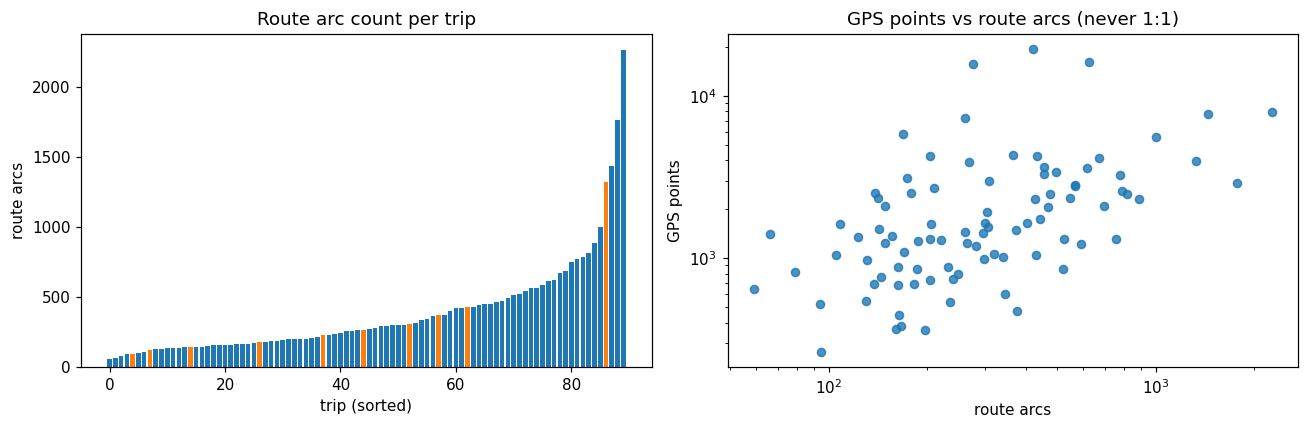

GPS points per route arc:
count    90.00
mean      8.14
std       8.98
min       1.26
25%       3.30
50%       5.25
75%       9.46
max      56.98


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = summary.sort_values("n_route_arcs")
ax[0].bar(np.arange(len(order)), order.n_route_arcs.to_numpy(),
          color=np.where(order.partition.to_numpy() == "train", "tab:blue", "tab:orange"))
ax[0].set(xlabel="trip (sorted)", ylabel="route arcs", title="Route arc count per trip")
ax[1].scatter(summary.n_route_arcs, summary.n_gps, s=28, alpha=0.8)
ax[1].set(xlabel="route arcs", ylabel="GPS points", xscale="log", yscale="log",
          title="GPS points vs route arcs (never 1:1)")
fig.savefig(FIG / "route_arc_count.png")
plt.show()

print("GPS points per route arc:")
print(summary.gps_per_route_arc.describe().round(2).to_string())

## 6. What this means for the next steps

Run the cells above for the live numbers; the points below are what the profile
implies for the pipeline.

1. **Never index `route[i]` by GPS point `i`.** There are many GPS points per
   route arc, and the ratio varies by an order of magnitude between trips, so
   Step 8 must align by geometry along the route, not by position.
2. **Long dwells on one arc are the norm, not an edge case.** A high
   points-per-arc ratio means stretches where many consecutive fixes belong to a
   single arc — the first failure mode to design the alignment around.
3. **Route chain breaks must reset distance accumulation.** Use
   `io_utils.route_segments()` so no phantom straight line is drawn across a gap.
4. **Per-trip CRS is mandatory.** The `utm_epsg` column varies across trips; a
   single fixed CRS would corrupt the Step 6 candidate radius.
5. **Graph size drives runtime**, not trip duration: the largest graph is ~100×
   the smallest, so the Step 6 R-tree must be built per trip and queried in bulk.
6. **Some trips carry a systematic GPS-to-network offset** of 100–250 m
   (see `frac_gps_within_50m_of_route`). For those, a fixed R = 50 m cannot
   contain the true arc, so the Step 6 miss rate will be dominated by data
   geometry, not by ranking quality. These trips need either a larger radius,
   an adaptive radius, or exclusion — a decision to take on the evidence in the
   table above, not silently.
7. **The road graph is fragmented**: nearly every trip's network splits into
   multiple connected components, so Step 8 cannot assume a path exists between
   consecutive arcs, and any graph-based smoothing must tolerate dead ends.